# SPKLU siting — how the two models work, in the order they were built

**This notebook needs no database.** It reads two committed artifacts:
`output/model_input_jabodetabek.parquet` (the training matrix) and the two
`.joblib` model files. Run it top to bottom.

**What is recomputed live, and what is read.** Everything about the *descriptive*
model is recomputed here from the parquet, so any number on screen can be
challenged and re-run. The *prescriptive* model's training rows are built from
the database inside `train_utilisation_model.py` and are not saved to disk, so
its numbers are read back from the metadata stored inside its `.joblib`. That is
stated at each point rather than blurred.

**The one sentence to carry through.** There are two models. Only one of them
ranks locations, and it is not the one that scores highest.

## 1 · The planner's question, and why the obvious model answers a different one

A planner asks: **where should the next charger go?**

The obvious way to model that is to learn what distinguishes places that have a
charger from places that do not. That model is easy to build, scores well, and
answers a different question: *where does a charger already tend to be?* In
Jabodetabek 1,080 of 1,236 stations are PLN's, so what it mostly learns is PLN's
own footprint. Ranked by it, the best places to build are the places already
built on. Section 6 measures exactly that.

So the project carries two models with two different jobs:

| | Descriptive — *siting* | Prescriptive — *utilisation* |
|---|---|---|
| Question | does this cell resemble one that has a charger? | how much demand would a connector here serve? |
| Type | `RandomForestClassifier` | `RandomForestRegressor` |
| Can it rank unbuilt land? | **no** | **yes** |
| Where it appears in the product | one background line, with a warning | **the colour on the map** |

## 2 · The data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib, os

OUT = "output"
df = pd.read_parquet(os.path.join(OUT, "model_input_jabodetabek.parquet"))

print(f"cells            : {len(df):,}")
print(f"columns          : {df.shape[1]}")
print(f"kota (areas)     : {df.kota.nunique()}")
print(f"cells with a charger today : {int(df.has_station.sum()):,} "
      f"({df.has_station.mean():.1%} of the grid)")
print()
print("Each row is one 500 m x 500 m square of Jabodetabek.")

cells            : 27,219
columns          : 40
kota (areas)     : 13
cells with a charger today : 885 (3.3% of the grid)

Each row is one 500 m x 500 m square of Jabodetabek.


### 2.1 Where the columns come from

Four families, all from open sources joined onto the same grid. None of them
describe an existing charger — that exclusion is deliberate and section 3
explains why.

In [2]:
fams = {
    "land use (OSM)":      [c for c in df.columns if c.startswith("lu_")],
    "POI counts (OSM)":    [c for c in df.columns if c.startswith("poi_")],
    "roads (OSM)":         [c for c in df.columns if "road" in c],
    "population (WorldPop)":[c for c in df.columns if c == "population"],
}
for name, cols in fams.items():
    print(f"{name:<24} {len(cols):>3} columns   e.g. {', '.join(cols[:3])}")

LEAK = {"station_count", "connector_count", "nearest_station_m", "stations_2km"}
present = LEAK & set(df.columns)
print(f"\nstation-derived columns present in the file : {sorted(present) if present else 'none'}")
print("They are excluded from the features below — see section 3.")

land use (OSM)             4 columns   e.g. lu_commercial_share, lu_industrial_share, lu_residential_share
POI counts (OSM)          30 columns   e.g. poi_airport_terminal, poi_bus_station, poi_cafe
roads (OSM)                2 columns   e.g. road_length_m, road_nodes
population (WorldPop)      1 columns   e.g. population

station-derived columns present in the file : none
They are excluded from the features below — see section 3.


## 3 · One rule that decides everything: no station-derived feature

`nearest_station_m`, `stations_2km` and friends answer *"is a station already
here?"* — which is the label, restated. A model given them scores beautifully and
is useless, because **an unbuilt cell cannot supply them**. They are dropped
before any model is fitted.

This is the same reason the target below is `has_station` rather than anything
about how busy a station is: the descriptive model is deliberately allowed to see
only what every cell in Jabodetabek can answer.

In [3]:
EXCLUDE = LEAK | {"cell_id", "kota", "geom", "centroid", "built_at", "overlap_frac",
                  "ordinal", "number_of_cells", "has_station"}
feats = [c for c in df.columns if c not in EXCLUDE and df[c].dtype.kind in "if"]
X = df[feats].fillna(0.0).values
y = df["has_station"].astype(int).values
groups = df["kota"].values

print(f"features used : {len(feats)}")
print(f"positive rate : {y.mean():.1%}  ({y.sum():,} of {len(y):,})")

features used : 37
positive rate : 3.3%  (885 of 27,219)


## 4 · Four estimators, compared on an identical split

Nothing here assumes a random forest is right. Four families are fitted on the
same stratified 80/20 split: a linear model, a distance model, a bagged tree
ensemble and a boosted one. Scale-sensitive ones get a `StandardScaler`.

**This split flatters all four**, and section 5 shows by how much. It is reported
first precisely so it can be discounted.

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             f1_score, balanced_accuracy_score)

RS = 42
models = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=15)":         make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "RandomForest (200)": RandomForestClassifier(200, random_state=RS, n_jobs=-1),
    "GradientBoosting":   GradientBoostingClassifier(random_state=RS),
}
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)

rows = []
for name, m in models.items():
    m.fit(Xtr, ytr)
    p, pred = m.predict_proba(Xte)[:, 1], m.predict(Xte)
    rows.append({"model": name, "AUC": roc_auc_score(yte, p),
                 "PR-AUC": average_precision_score(yte, p),
                 "F1": f1_score(yte, pred),
                 "bal.acc": balanced_accuracy_score(yte, pred)})
split = pd.DataFrame(rows).set_index("model").round(3)
print(split.to_string())
print(f"\nPR-AUC of always answering 'no station': {y.mean():.3f}")

                      AUC  PR-AUC     F1  bal.acc
model                                            
LogisticRegression  0.921   0.372  0.304    0.599
KNN (k=15)          0.837   0.328  0.213    0.561
RandomForest (200)  0.930   0.431  0.265    0.583
GradientBoosting    0.931   0.412  0.324    0.610

PR-AUC of always answering 'no station': 0.033


## 5 · Why that table cannot be believed, and what replaces it

The grid is 500 m. Neighbouring squares share roads, shops and residents, so a
random split puts a cell in training and its neighbour in test. The model is
substantially **looking up an answer it has already seen 500 m away**. That is
spatial leakage, and it is the single most common way a geographic model reports
a score it cannot reproduce anywhere new.

The honest protocol holds out **one whole kota at a time** — leave-one-area-out.
Every cell of that kota is unseen, including its neighbours. It answers the
question the planner is actually asking: *does this work somewhere we have not
modelled?*

The cell below fits 13 forests, one per held-out kota. It also keeps the
out-of-fold probabilities, which section 6 needs.

In [5]:
oof = np.full(len(df), np.nan)
rows = []
for kota in sorted(df.kota.dropna().unique()):
    te = (df.kota == kota).values
    tr = ~te
    if len(np.unique(y[te])) < 2 or te.sum() < 30:
        rows.append({"kota": kota, "cells": int(te.sum()),
                     "positive": y[te].mean(), "AUC": np.nan}); continue
    m = RandomForestClassifier(200, random_state=RS, n_jobs=-1).fit(X[tr], y[tr])
    p = m.predict_proba(X[te])[:, 1]
    oof[te] = p
    rows.append({"kota": kota, "cells": int(te.sum()),
                 "positive": y[te].mean(), "AUC": roc_auc_score(y[te], p)})

loco = pd.DataFrame(rows)
print(loco.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
loco_mean = loco.AUC.mean()
print(f"\nLOCO AUC (mean over areas) : {loco_mean:.4f}   <- the number to report")
print(f"best random-split AUC      : {split.AUC.max():.4f}   <- the number to discount")
print(f"gap                        : {split.AUC.max() - loco_mean:.4f}")

                  kota  cells  positive   AUC
                Bekasi   5083     0.009 0.864
                 Bogor  11971     0.005 0.879
           Kota Bekasi    862     0.059 0.794
            Kota Bogor    448     0.038 0.808
            Kota Depok    789     0.044 0.834
    Kota Jakarta Barat    502     0.159 0.747
    Kota Jakarta Pusat    191     0.414 0.723
  Kota Jakarta Selatan    583     0.249 0.800
    Kota Jakarta Timur    733     0.139 0.731
    Kota Jakarta Utara    562     0.123 0.783
        Kota Tangerang    725     0.081 0.801
Kota Tangerang Selatan    657     0.093 0.838
             Tangerang   4113     0.019 0.895

LOCO AUC (mean over areas) : 0.8074   <- the number to report
best random-split AUC      : 0.9310   <- the number to discount
gap                        : 0.1236


### How to read the gap

The gap is **the finding, not a defect.** It measures how much of the apparent
skill was neighbours recognising neighbours. Reporting 0.80 instead of 0.93 is
not modesty: the higher number answers a question nobody asked, because no
planner ever needs a prediction for a cell whose neighbour is already labelled.

A per-kota table also shows *where* the model is weak, which a single averaged
number hides.

## 6 · The measurement that forces a second model

If the descriptive model were a siting tool, its highest-ranked cells would be
good places to build. So take its highest-ranked cells and ask how many already
have a charger.

**Rank them twice.** Once with the model scoring the same cells it was fitted on,
and once with the out-of-fold probabilities from section 5, where every cell was
scored by a model that had never seen its kota. The two answers differ enough to
matter, and the difference is the same lesson as section 5 — applied here to this
project's own headline claim.

In [6]:
insample = RandomForestClassifier(200, random_state=RS, n_jobs=-1).fit(X, y)
p_in = insample.predict_proba(X)[:, 1]
order_in = np.argsort(-p_in)
ranked_oof = df.assign(p=oof).dropna(subset=["p"]).sort_values("p", ascending=False)

print(f"{'top-k':>8}{'in-sample':>12}{'out-of-fold':>14}")
for k in (100, 500, 1000):
    print(f"{k:>8}{y[order_in[:k]].mean():>11.1%}"
          f"{ranked_oof.head(k).has_station.mean():>14.1%}")
base = df.has_station.mean()
print(f"\nbase rate across the grid : {base:.1%}")
print(f"out-of-fold top-500 enrichment : {ranked_oof.head(500).has_station.mean()/base:.0f}x the base rate")

   top-k   in-sample   out-of-fold
     100     100.0%         69.0%
     500     100.0%         50.0%
    1000      88.4%         39.1%

base rate across the grid : 3.3%
out-of-fold top-500 enrichment : 15x the base rate


### Which column to quote, and why it is the smaller one

The in-sample column reads 100% at the top 500. It is also the number this
project has been quoting — in `train_utilisation_model.py`, in the frontend
comments, and in the methodology report. **It should be the out-of-fold column
instead.** A forest fitted on 27,219 cells and then asked to rank those same
cells is partly reciting labels it has memorised, which is the identical mistake
section 5 exists to expose. Applying our own standard to our own headline claim
is not a concession; leaving it unapplied is what a supervisor would find.

The honest column still settles the argument decisively: **50% of the top 500 are
already built, against a base rate of 3.3%** — a fifteen-fold enrichment toward
land that is already occupied. A ranking that concentrates that hard on built
land cannot tell a planner where to build.

The model is not broken. It is answering its own question correctly, and that
question is the wrong one. The right response is a different model, not a
better-tuned one — which is what section 8 is.

In the product this model therefore appears as one background line — *"7% like an
existing charger site"* — under an explicit warning that a high figure is not a
recommendation.

## 7 · Which feature families carry the signal

Before moving on, one ablation, so the descriptive model's skill is attributed
rather than assumed. Each row is a full leave-one-area-out run using only that
family. Read from the artifact written by `train_siting_model.py`.

In [7]:
abl = pd.read_csv(os.path.join(OUT, "ablation_jabodetabek.csv"))
print(abl.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

           feature_set  n_features  loco_auc
       population only           1    0.5076
            roads only           2    0.5556
         land use only           4    0.6663
              POI only          30    0.7413
    population + roads           3    0.5775
pop + roads + land use           7    0.7351
            everything          37    0.8030


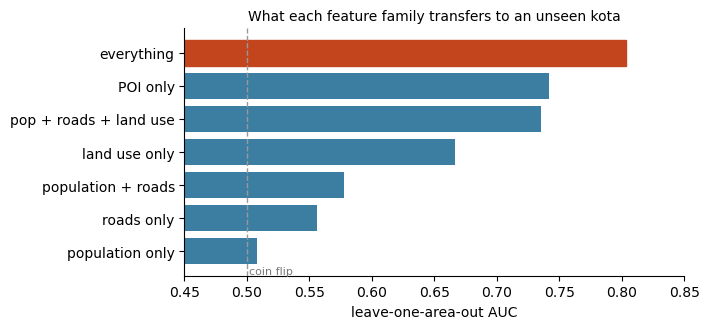

In [8]:
import matplotlib.pyplot as plt
a = abl.sort_values("loco_auc")
fig, ax = plt.subplots(figsize=(7.2, 3.4))
bars = ax.barh(a.feature_set, a.loco_auc, color="#3b7ea1")
bars[list(a.feature_set).index("everything")].set_color("#c2451e")
ax.axvline(0.5, color="#999", ls="--", lw=1)
ax.text(0.502, -0.45, "coin flip", color="#777", fontsize=8, va="top")
ax.set_xlim(0.45, 0.85); ax.set_xlabel("leave-one-area-out AUC")
ax.set_title("What each feature family transfers to an unseen kota", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Population alone scores 0.508 — a coin flip.** That is worth saying out loud,
because population is the feature everyone expects to dominate an EV-charging
model. It does not: people are everywhere in Jabodetabek, and what separates a
charger location from its neighbour is what the land is *used for*. POI counts
alone reach 0.741.

## 8 · The prescriptive model — the one the map actually uses

From here the numbers are **read from the trained artifact**, not recomputed:
its training rows are assembled from the live database by
`train_utilisation_model.py` and are not committed to disk.

In [9]:
art = joblib.load(os.path.join(OUT, "utilisation_model.joblib"))
for k in ("target", "target_units", "n_samples", "window_days",
          "window_start", "window_end", "dose_response_q4_over_q1",
          "median_sessions_per_cell", "loco_r2", "random_split_r2", "label"):
    v = art[k]
    v = round(v, 4) if isinstance(v, float) else v
    print(f"{k:<28} {v}")

target                       sessions_per_conn_day
target_units                 simulated charging sessions per connector per day
n_samples                    881
window_days                  6
window_start                 2026-08-21T00:00:00+07:00
window_end                   2026-08-27T00:00:00+07:00
dose_response_q4_over_q1     1.6951
median_sessions_per_cell     86.0
loco_r2                      0.7508
random_split_r2              0.7434
label                        utilisation SCENARIO (recovers the demand assumption in migrations 0023/0024, not a forecast)


### 8.1 What it predicts, and why that target

The target is **sessions per connector per day** — demand volume, which is what a
planner is buying.

The obvious alternative, *occupancy* (how full the hardware looks), was tried and
is wrong here, for a reason worth showing a supervisor because it is not
obvious: occupancy is sessions × duration ÷ capacity, and duration is energy ÷
power. Busy locations hold **faster** chargers, so serving more drivers faster
reads as *less* occupied. Occupancy therefore moved **against** demand. The
ablation below settles that with the metric rather than with the argument —
`duty` is occupancy computed properly, and it still loses.

In [10]:
ab = pd.DataFrame(art["ablation"]).rename(
    columns={"loco": "LOCO R2", "random": "random R2", "arm": "feature set"})
print(ab.to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
best = ab.loc[ab["LOCO R2"].idxmax()]
print(f"\nchosen: {best.target} / {best['feature set']}   LOCO R2 {best['LOCO R2']:+.4f}")

                    target         feature set  LOCO R2  random R2
     sessions_per_conn_day       location only  +0.1183    +0.0929
     sessions_per_conn_day location + hardware  +0.7508    +0.7434
sessions_per_free_conn_day       location only  +0.1689    +0.1478
sessions_per_free_conn_day location + hardware  +0.5157    +0.5036
                      duty       location only  +0.0448    +0.0663
                      duty location + hardware  +0.2416    +0.2411

chosen: sessions_per_conn_day / location + hardware   LOCO R2 +0.7508


### 8.2 Read the table by columns, not by the winning row

- **Every `location only` row is weak** (+0.04 to +0.17). Location alone barely
  predicts how busy a connector will be.
- **Adding hardware transforms the top row** (+0.118 → +0.751). Hardware, not
  location, carries most of this target.
- **`duty` loses under both feature sets**, which is defect 1 above, measured.

An earlier version of this model scored **LOCO R² = −0.1219** — worse than
predicting the mean. Three defects compounded: the target cancelled the signal
(occupancy), the training window was diluted with unweighted days, and hardware
was excluded so its variance hid in the residual. The fix for the third is the
`location + hardware` arm you see winning here.

### 8.3 The hardware confounder, and how a fair comparison survives it

In [11]:
m, cols = art["model"], art["feature_names"]
imp = pd.DataFrame({"feature": cols, "importance": m.feature_importances_}) \
        .sort_values("importance", ascending=False)
print(imp.head(8).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
hw = imp[imp.feature.isin(["avg_kw", "connectors"])].importance.sum()
print(f"\nhardware share (avg_kw + connectors) : {hw:.1%}")
print(f"reference spec used when scoring an unbuilt cell : {art['reference_spec']}")

             feature  importance
              avg_kw      0.6364
          population      0.1993
poi_place_of_worship      0.0300
          road_nodes      0.0293
       road_length_m      0.0257
           poi_total      0.0118
lu_residential_share      0.0106
          connectors      0.0081

hardware share (avg_kw + connectors) : 64.4%
reference spec used when scoring an unbuilt cell : {'connectors': 2.0, 'avg_kw': 22.0}


`avg_kw` alone carries most of the model. If cells were scored with their own
hardware, the ranking would mostly rank *chargers*, not *places* — and an unbuilt
cell has no hardware to supply anyway.

So every cell is scored at the **same reference spec**, held at the median of
what is actually built. The question becomes *"a typical installation, placed
here"*, and the only thing that varies between cells is location. That is what
makes the comparison fair, and it is why hardware can be in the model without
contaminating the ranking.

## 9 · From a prediction to the colour on the map

The prediction is not the score. A cell can have high demand and three chargers
already inside 2 km. The score discounts it by nearby supply:

$$\text{discount} = \frac{1}{1+\sigma}, \qquad
S = w \cdot \text{pct-rank}(\hat{u}) + (1-w)\cdot \text{discount}$$

where $\sigma$ is effective supply within 2 km. This is the equal-attraction case
of a Huff market-share model: with $\sigma$ competitors of equal pull, a new site
takes $1/(1+\sigma)$ of the demand.

**One detail that had to be measured, not assumed.** The prediction is
percentile-ranked; the discount is **not**. 65% of the grid has nothing within
2 km and is tied at exactly 1.0, so ranking the discount collapses it into a step
function — its 50th, 90th and 99th percentiles all read 1.000. Ranking it pinned
9,581 of 9,625 contested cells below the yellow floor. Using the raw discount
took contested cells reaching yellow from 44 to 565.

The red and yellow floors are **regional percentiles recomputed per response**,
not fixed constants, so the bands survive a retrain.

## 10 · What this model is not

**It is not a forecast.** Every charging session in the database is simulation
output. Migrations 0023/0024 weight each station's session probability by its
cell's population, POI activity and road nodes — so the sessions encode *that
assumption*, and this model recovers it. It is a scenario tool: *"if demand
follows those three features with those weights, here is where utilisation
lands."* The weights are the thing to argue about, not the output.

The label is stored inside the artifact itself, so it travels with the model:

In [12]:
print(art["label"])
print()
print("window selected by :", art["window_selected_by"])
print("dose-response Q4/Q1:", round(art["dose_response_q4_over_q1"], 3),
      " (measured; the trainer refuses below 1.35)")

utilisation SCENARIO (recovers the demand assumption in migrations 0023/0024, not a forecast)

window selected by : measured dose-response per day, not computed_at
dose-response Q4/Q1: 1.695  (measured; the trainer refuses below 1.35)


### Two more limits to state before anyone asks

1. **The supply discount counts stations, not connectors.** Ten single-connector
   sites and one ten-connector site look identical to it.
2. **A random forest cannot extrapolate.** It predicts within the range of what
   it has seen; a cell unlike anything in the training set gets a confident
   answer it has not earned.

### What would make it a forecast

Replacing the simulated target with real telemetry. Nothing else changes — not
the features, not the validation design, not the serving path. **The temporary
thing here is the data, not the architecture**, which is the distinction worth
defending.

## Summary — the four claims, and where each was measured

| Claim | Where in this notebook |
|---|---|
| A random split overstates a spatial model's skill | §5 — 0.93 vs 0.80 on identical data |
| The descriptive model cannot rank unbuilt land | §6 — 50% of its top 500 are built, vs a 3.3% base rate |
| Population is not the driver everyone expects | §7 — 0.508, a coin flip, alone |
| The map's score is prescriptive, not descriptive | §8–9 — target, ablation, blend |